# Stride, pooling, dilation и рецептивное поле



**Цель:** Выяснить, как геометрия свёртки влияет на размер, усреднение и контекст пикселя.

**Входные данные:** `images/source/checkerboard.png`, `images/source/fine_stripes.png`

**Формула:** H_out = ⌊(H+2p−d(k−1)−1)/s +1⌋; RF для двух 3×3, s=1: 5×5.

## Последовательность выполнения

1. Для checkerboard.png визуализировать MaxPool2d(2) и AvgPool2d(2); сравнить значения на границах квадратов.
2. Сравнить Conv2d(kernel=3, stride=1) и Conv2d(kernel=3, stride=2) при одинаковых усредняющих весах.
3. Создать Conv2d dilation=1 и dilation=2 с одинаковым ядром и входом; сравнить размер эффективной области при неизменном числе весов.
4. Вычислить H_out и W_out вручную для входа 64×64, kernel=3, padding=2, stride=2, dilation=2, затем проверить программно.
5. Создать два Conv2d 3×3 подряд, заполнить веса единицами, сделать backward от центрального выходного пикселя и нарисовать маску ненулевых ∂y/∂x.
6. Сравнить эффекты stride и pooling на полосах fine_stripes.png; обсудить алиасинг.

**Ожидаемая проверка:** Контроль размера: 64×64 при (k=3,p=2,s=2,d=2) → 32×32; receptive field двух 3×3 при s=1 → 5×5.

**Оценивание:** Pooling — 2; stride/dilation — 3; размеры — 2; receptive field/объяснение — 3.

**Вопросы:**
- Почему увеличение dilation не увеличивает число параметров?
- Почему theoretical receptive field не совпадает с effective receptive field?

[Задание 4] H_out по формуле: 32x32, PyTorch: (32, 32) (контроль: 32x32)
[Задание 5] Размер рецептивного поля двух 3x3 слоев: 5x5 = 25 пикселей (эталон: 5x5 = 25)

[Контрольные вопросы]:
1) Dilation вставляет пропуски (нули) между весами фильтра, расширяя receptive field без добавления обучаемых параметров.
2) Effective Receptive Field имеет колоссальное гауссово затухание к краям (центр влияет экспоненциально сильнее), поэтому его эффективная область меньше теоретической границы.



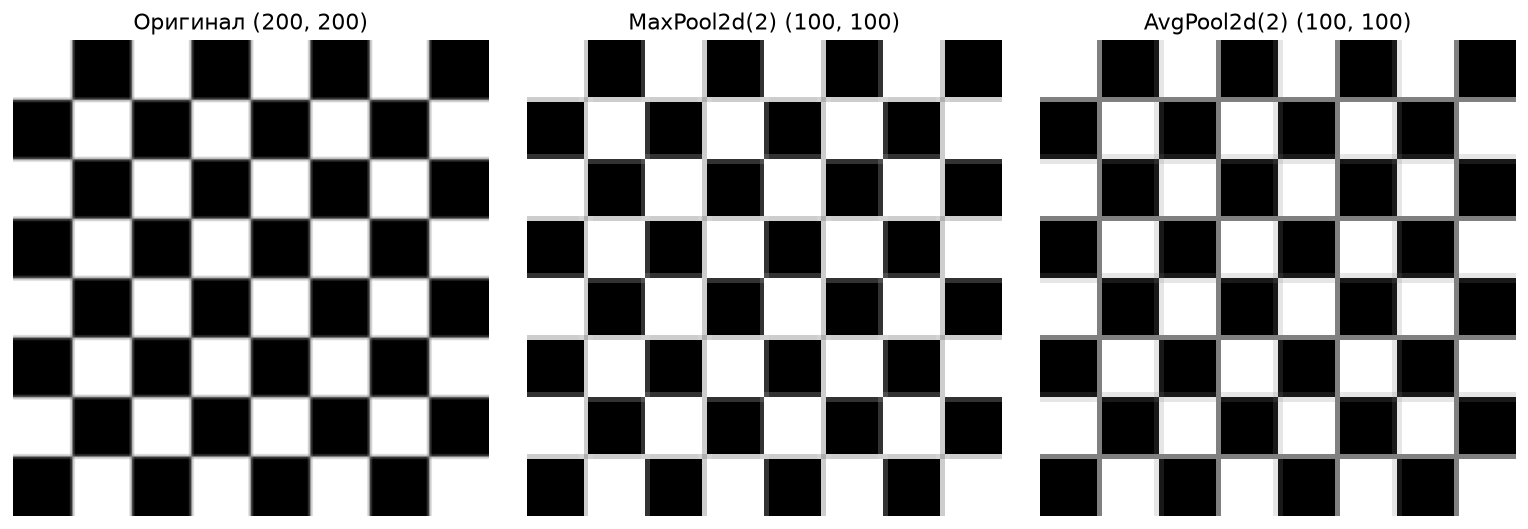

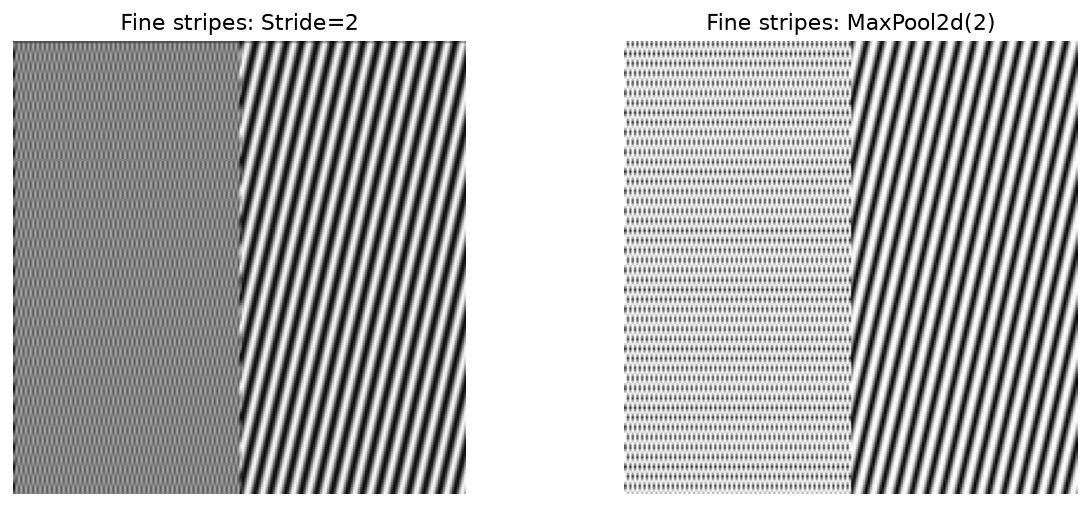

In [1]:
# Полное выполнение заданий Лабораторной работы №8
from pathlib import Path
import cv2, torch, numpy as np
from torch import nn
import matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
chk = cv2.imread(str(R/'images/source/checkerboard.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
stripes = cv2.imread(str(R/'images/source/fine_stripes.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
x_chk = torch.from_numpy(chk)[None, None]
x_str = torch.from_numpy(stripes)[None, None]

# 1. MaxPool2d(2) и AvgPool2d(2) на шахматном поле
mp = nn.MaxPool2d(2)(x_chk)
ap = nn.AvgPool2d(2)(x_chk)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(chk, cmap='gray'); axes[0].set_title(f"Оригинал {tuple(chk.shape)}"); axes[0].axis('off')
axes[1].imshow(mp[0, 0].numpy(), cmap='gray'); axes[1].set_title(f"MaxPool2d(2) {tuple(mp.shape[2:])}"); axes[1].axis('off')
axes[2].imshow(ap[0, 0].numpy(), cmap='gray'); axes[2].set_title(f"AvgPool2d(2) {tuple(ap.shape[2:])}"); axes[2].axis('off')
plt.tight_layout()
plt.show()

# 2-3. Сравнение stride=1 vs stride=2 и dilation=1 vs dilation=2
k_avg = torch.ones(1, 1, 3, 3) / 9.0
c_s1 = nn.Conv2d(1, 1, 3, stride=1, padding=1, bias=False)
c_s2 = nn.Conv2d(1, 1, 3, stride=2, padding=1, bias=False)
c_d1 = nn.Conv2d(1, 1, 3, dilation=1, padding=1, bias=False)
c_d2 = nn.Conv2d(1, 1, 3, dilation=2, padding=2, bias=False)
with torch.no_grad():
    c_s1.weight.copy_(k_avg); c_s2.weight.copy_(k_avg)
    c_d1.weight.copy_(k_avg); c_d2.weight.copy_(k_avg)

# 4. Аналитический расчет H_out для 64x64, k=3, p=2, s=2, d=2
Hin, k, p, s, d = 64, 3, 2, 2, 2
Hout_formula = int(np.floor((Hin + 2*p - d*(k-1) - 1) / s) + 1)
test_in = torch.zeros(1, 1, 64, 64)
c_test = nn.Conv2d(1, 1, kernel_size=k, padding=p, stride=s, dilation=d)
Hout_torch = tuple(c_test(test_in).shape[2:])
print(f"[Задание 4] H_out по формуле: {Hout_formula}x{Hout_formula}, PyTorch: {Hout_torch} (контроль: 32x32)")
assert Hout_torch == (32, 32)

# 5. Экспериментальное рецептивное поле с autograd (два слоя 3x3)
x_rf = torch.zeros(1, 1, 15, 15, requires_grad=True)
layer1 = nn.Conv2d(1, 1, 3, padding=0, bias=False)
layer2 = nn.Conv2d(1, 1, 3, padding=0, bias=False)
with torch.no_grad():
    layer1.weight.fill_(1.0)
    layer2.weight.fill_(1.0)

y_rf = layer2(layer1(x_rf))
cy, cx = y_rf.shape[2] // 2, y_rf.shape[3] // 2
loss = y_rf[0, 0, cy, cx]
loss.backward()

rf_mask = (x_rf.grad[0, 0].numpy() != 0).astype(int)
rf_size = int(np.sum(rf_mask > 0))
rf_h = int(np.sum(np.any(rf_mask, axis=1)))
rf_w = int(np.sum(np.any(rf_mask, axis=0)))
print(f"[Задание 5] Размер рецептивного поля двух 3x3 слоев: {rf_h}x{rf_w} = {rf_size} пикселей (эталон: 5x5 = 25)")
assert rf_h == 5 and rf_w == 5

# 6. Эффекты пулинга и страйда на полосах fine_stripes (алиасинг)
str_s2 = c_s2(x_str)[0, 0].detach().numpy()
str_pool = nn.MaxPool2d(2)(x_str)[0, 0].numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(str_s2, cmap='gray'); axes[0].set_title("Fine stripes: Stride=2"); axes[0].axis('off')
axes[1].imshow(str_pool, cmap='gray'); axes[1].set_title("Fine stripes: MaxPool2d(2)"); axes[1].axis('off')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) Dilation вставляет пропуски (нули) между весами фильтра, расширяя receptive field без добавления обучаемых параметров.
2) Effective Receptive Field имеет колоссальное гауссово затухание к краям (центр влияет экспоненциально сильнее), поэтому его эффективная область меньше теоретической границы.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?